# EXPLORATORY DATA ANALISIS
### Getting familiar with the dataset

In [1]:
import matplotlib.pyplot as plt

In [2]:
from torchvision.datasets import ImageFolder

#Importing the dataset
train_data = ImageFolder(root="./data/Train")
print(f"#Training examples: {len(train_data)}")

#Training examples: 39209


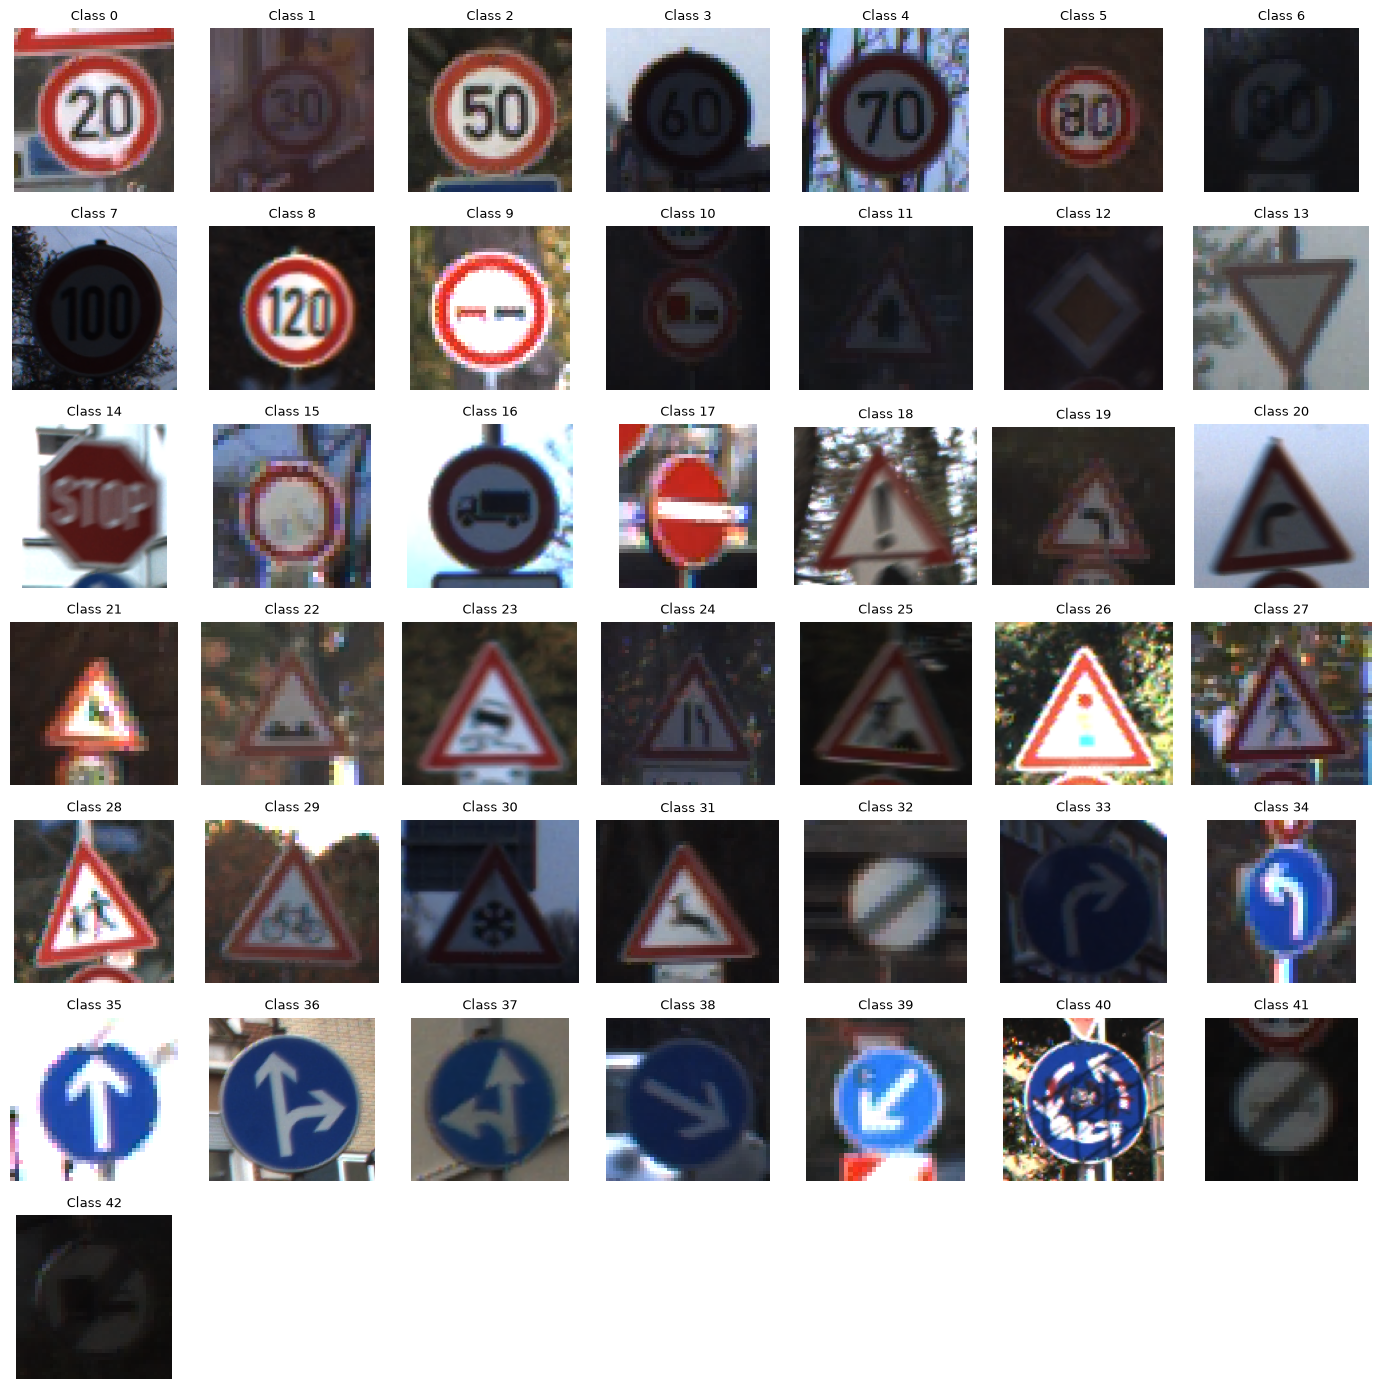

In [3]:
#Let's visualize some samples
import random
from PIL import Image

classes = train_data.classes

paths_by_class = {}
for path_, label in train_data.samples:
    paths_by_class.setdefault(label, []).append(path_)

fig, axes = plt.subplots(7, 7, figsize=(14, 14))
for ax in axes.flat:
    ax.axis("off")

order = sorted(range(len(classes)), key=lambda i: int(classes[i]))
for ax, label in zip(axes.flat, order):
    img = Image.open(random.choice(paths_by_class[label]))
    ax.imshow(img)
    ax.set_title(f"Class {classes[label]}", fontsize=9)

plt.tight_layout()
plt.show()

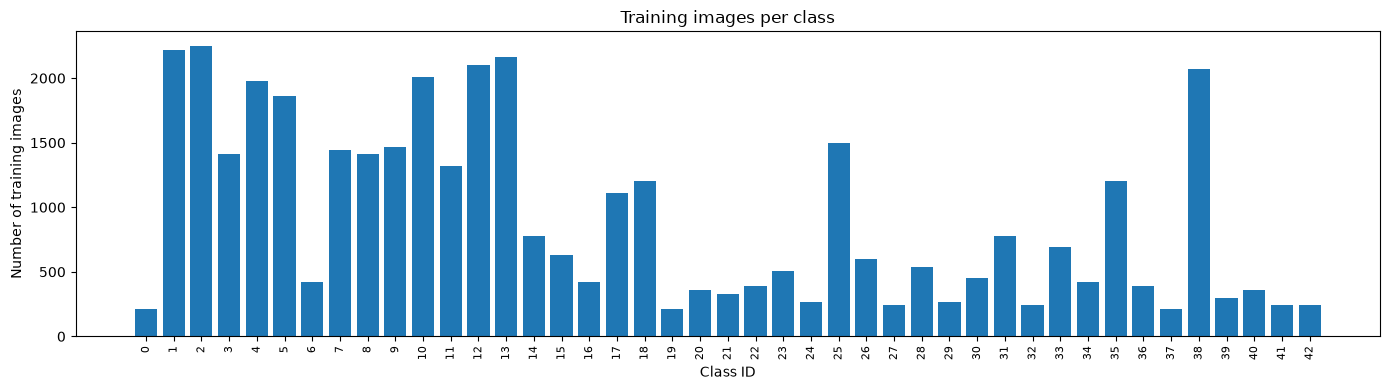

Largest class: 2250, smallest class: 210
Imbalance ratio: 10.7x


In [4]:
#Let's see hoy many samples per class we have
from collections import Counter

counts = Counter(train_data.targets)
ids = [int(classes[i]) for i in order]
values = [counts[i] for i in order]

plt.figure(figsize=(14, 4))
plt.bar(range(len(values)), values)
plt.xticks(range(len(values)), ids, rotation=90, fontsize=8)
plt.xlabel("Class ID")
plt.ylabel("Number of training images")
plt.title("Training images per class")
plt.tight_layout()
plt.show()

print(f"Largest class: {max(values)}, smallest class: {min(values)}")
print(f"Imbalance ratio: {max(values) / min(values):.1f}x")

We can notice a clear imbalance between the classes.
This imbalance matches the frequency of that signals in real life.
This would cause problems fitting that underrepresented classes.
We would need to find solutions!!

Now let's see our images size (px). 
Because going throught all the images would cost a lot of time I would copy-paste the results directly in the cells below.

![Class distribution](./data/Analysis/ImageSizeHistograms.png)

![Class distribution](./data/Analysis/ImageSizeScatterPlot.png)

count    1307.000000
mean       29.999235
std         0.027661
min        29.000000
25%        30.000000
50%        30.000000
75%        30.000000
max        30.000000
dtype: float64
Total tracks: 1307


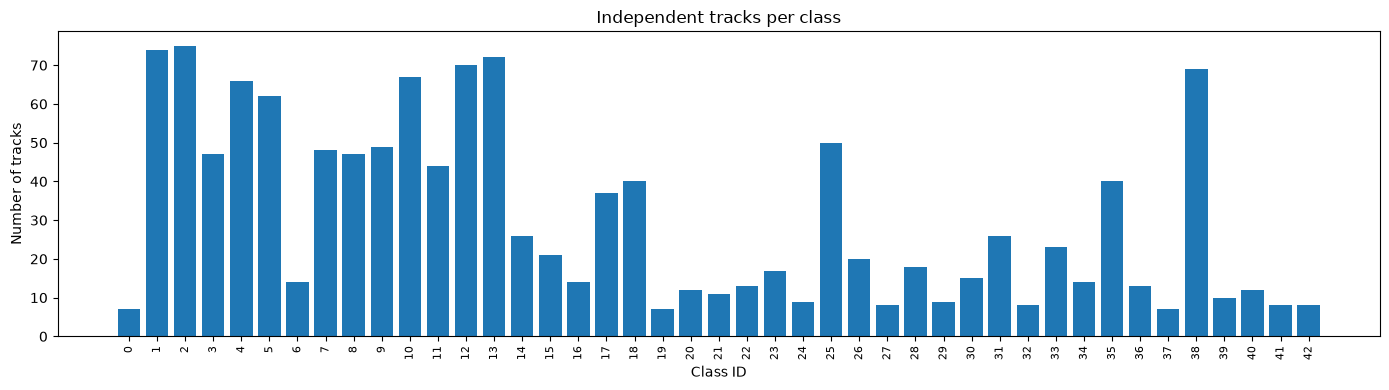

In [5]:
#Now let's check how many tracks they are
import os
import pandas as pd

rows = []
for path_, label in train_data.samples:
    stem = os.path.splitext(os.path.basename(path_))[0]
    parts = stem.split("_")
    rows.append({"path": path_, "label": label, "track": parts[-2], "frame": int(parts[-1])})

df_tracks = pd.DataFrame(rows)

df_tracks["group"] = df_tracks["label"].astype(str) + "_" + df_tracks["track"]

frames_per_track = df_tracks.groupby("group").size()
print(frames_per_track.describe())
print("Total tracks:", df_tracks["group"].nunique())

tracks_per_class = df_tracks.groupby("label")["group"].nunique()
tracks_per_class.index = [int(train_data.classes[i]) for i in tracks_per_class.index]
tracks_per_class = tracks_per_class.sort_index()

plt.figure(figsize=(14, 4))
plt.bar(range(len(tracks_per_class)), tracks_per_class.values)
plt.xticks(range(len(tracks_per_class)), tracks_per_class.index, rotation=90, fontsize=8)
plt.xlabel("Class ID")
plt.ylabel("Number of tracks")
plt.title("Independent tracks per class")
plt.tight_layout()
plt.show()

# Conclusions

## 1. Class imbalance
The main problem we have noticed during the EDA is the imbalance between classes. Some classes have more than 70 tracks (these are also the most frequent signs on the street, e.g. the 30 km/h speed limit and yield), while others have fewer than 10. We could expect our model to perform worse on the rare classes.

To address this, we will compare several techniques against a baseline:
- Data augmentation (e.g. exposure changes and small rotations). I will not use horizontal flips, since mirroring can change the meaning of a sign.
- Class weights in the loss.
- Oversampling with `WeightedRandomSampler`.

The imbalance also affects the validation split. I will split by track to avoid leakage, and I will stratify by class so that every class appears in both the training and validation sets. Otherwise, some rare classes could end up with no tracks in validation.

## 2. Image size
The images have different sizes, so we would need to resize all of them to the same size.
- **Aspect ratio:** the mean is practically 1, so we can resize to a square without much distortion.
- **Pixels:** the median size (percentile 50) is about 43 px, so sizes far from that would mean resizing many images. Going too small means losing the details that distinguish similar signs (e.g. speed limits). Going too large (the maximum is 243 px) adds little information and increase the computation time significantly.

I will test {32, 48, 64} and choose the smallest size whose results are close to the best one.

## 3. Training strategy
1. I will first train a baseline model without any of the techniques above, and compute its macro F1 and the recall of each class.
2. Then I will apply one improvement at a time, keeping the architecture, seed and split identical, and compare each result with the baseline. We would need to pay special attention to the rare classes.
3. Finally, I will evaluate my best model once on the test set, and also on some signs from Spain (as a qualitative extra, since some designs differ from the German ones).

I did not use the test set during the exploration, to avoid leakage. Now it's time to build the model!